# Day 17 - Light and Dark

This notebook uses the cityshade Python library downloaded from https://janosovm.gumroad.com/l/cityshade. It calculates the amount of direct sunlight Rjukan would receive during summer and winter, without any interventions from the mirrors on the mountains.

### 1. Setup

In [3]:
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from shapely.geometry import Point
import cityshade as cs
from matplotlib.colors import LinearSegmentedColormap, LightSource, Normalize
from scipy import ndimage as ndi
from matplotlib.lines import Line2D

In [4]:
# SETTINGS: change these to map a different place or date
TOWN   = (59.8784, 8.5935)   # Rjukan centre
SQUARE = (59.8781, 8.5938)   # Rjukan town square
TZ     = "Europe/Oslo"       # local time zone
RADIUS = 4000                # metres from the centre to the map edge;
CELL   = 10.0                # size of one grid cell in metres
DARK, LIGHT = "2025-12-21", "2026-03-20"
CACHE = Path("cache"); CACHE.mkdir(exist_ok=True) # folder for downloaded data, so we fetch it once

In [5]:
# Buildings from OpenStreetMap, turned into a height grid
rjukan = cs.from_osm(TOWN, radius=RADIUS, cell=CELL, include_parts=False)

# Add the mountains (Copernicus elevation data)
ground_file = CACHE / "rjukan_ground.npy"
if ground_file.exists():
    cs.add_terrain(rjukan, verbose=False, ground=np.load(ground_file))
else:
    cs.add_terrain(rjukan)                       # Copernicus DEM, downloads once
    np.save(ground_file, rjukan.ground)

rjukan.report()
print(f"grid {rjukan.shape}, relief {rjukan.ground.max() - rjukan.ground.min():.0f} m")

# # Find the town square in the grid
def to_pixel(latlon, s):
    p = gpd.GeoSeries([Point(latlon[1], latlon[0])], crs="EPSG:4326").to_crs(s.crs).iloc[0]
    col, row = ~s.transform * (p.x, p.y)
    return int(row), int(col)

r, c = to_pixel(SQUARE, rjukan)
sq = lambda g: g[r-1:r+2, c-1:c+2].mean()        # sample 30 x 30 m around the square

C:\Users\User\anaconda3\envs\myenv\Lib\site-packages\networkx\utils\backends.py:102: RuntimeWarning: networkx backend name is not a valid identifier: 'nx-loopback'. Ignoring.
  backends = _get_backends("networkx.backends")


fetching OSM buildings for 59.8784, 8.5935 ...
59.8784, 8.5935
  grid        806 x 807 cells at 10 m = 8.07 x 8.06 km
  centre      59.87840, 8.59350
  buildings   2046 footprints, 0.5% of cells built, tallest 67 m
  heights     19.7% of built area from real OSM tags, the rest estimated
  terrain     flat ground assumed
59.8784, 8.5935
  grid        806 x 807 cells at 10 m = 8.07 x 8.06 km
  centre      59.87840, 8.59350
  buildings   2046 footprints, 0.5% of cells built, tallest 67 m
  heights     19.7% of built area from real OSM tags, the rest estimated
  terrain     1585 m of relief, from a supplied model
grid (806, 807), relief 1585 m


### 2. Calculate sun hours for the days selected

In [7]:
dark  = cs.sun_hours(rjukan, DARK,  tz=TZ, step_minutes=5)
light = cs.sun_hours(rjukan, LIGHT, tz=TZ, step_minutes=5)

# sanity checks
print(f"max anywhere:  Dec {dark.max():.1f} h  |  Mar {light.max():.1f} h")
print(f"town square:   Dec {sq(dark):.1f} h  |  Mar {sq(light):.1f} h")
print(f"grid with zero sun in December: {(dark == 0).mean():.0%}")

max anywhere:  Dec 5.8 h  |  Mar 12.1 h
town square:   Dec 0.0 h  |  Mar 0.3 h
grid with zero sun in December: 42%


### 3. Plot the map

building cells: 0.47%  (Cell 1 report said 0.5% built)
December sun at the mirror site: 1.9 h
December sun at the mirror site: 1.9 h


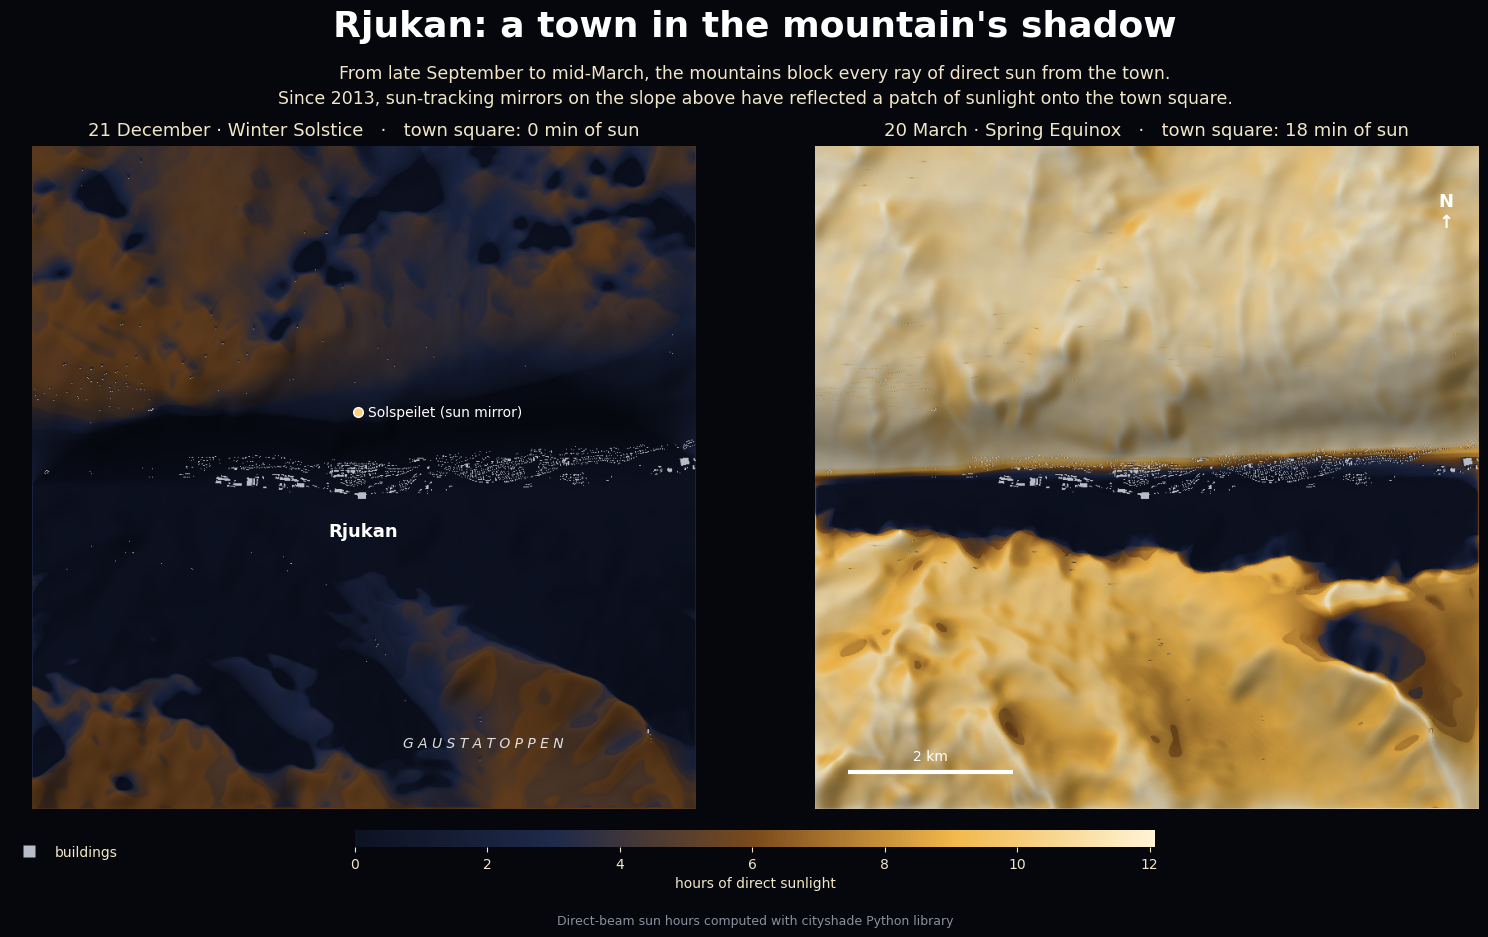

In [9]:
# cityshade stores two height grids:
#   rjukan.ground = terrain height        rjukan.dsm = surface the sun hits
# A building is where the surface stands more than 1 m above the ground.
height_above_ground = rjukan.dsm - rjukan.ground

# Safety check: if many cells come out negative, dsm already holds
# heights above ground (not elevations), so use it directly.
if (height_above_ground < -0.5).mean() > 0.01:
    height_above_ground = rjukan.dsm

buildings = height_above_ground > 1.0
print(f"building cells: {buildings.mean():.2%}  (Cell 1 report said 0.5% built)")

# colours
# Sun hours: night blue (0 h) -> brown -> gold -> pale cream (12 h)
night_to_gold = LinearSegmentedColormap.from_list(
    "night_to_gold", ["#0d1222", "#1f2a4a", "#7a4a1c", "#f2b84b", "#fff4d6"])
norm = Normalize(0, light.max())     # same 0-12 h scale for both panels

BUILDING_GREY = (0.72, 0.74, 0.78)
INK, BG = "#f2e6c8", "#05070d"   

# hillshade: light-and-shadow texture that makes the mountains look 3D
relief = LightSource(azdeg=315, altdeg=40).hillshade(
    rjukan.ground, vert_exag=1.5, dx=CELL, dy=CELL)

def paint(hours):
    """Turn a sun-hours grid into an RGB image."""
    rgb = night_to_gold(norm(hours))[..., :3]          # colour by sun hours
    rgb = rgb * (0.4 + 0.6 * relief[..., None])        # add mountain texture
    rgb[buildings] = BUILDING_GREY                     # draw the town
    return np.clip(rgb, 0, 1)

# both panels side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 9.6), facecolor=BG)
fig.subplots_adjust(left=0.02, right=0.98, top=0.83, bottom=0.14, wspace=0.04)

panels = ((dark,  "21 December · Winter Solstice"),
          (light, "20 March · Spring Equinox"))
for ax, (hours, label) in zip(axes, panels):
    ax.imshow(paint(hours))
    ax.set_axis_off()
    ax.set_title(f"{label}   ·   town square: {sq(hours)*60:.0f} min of sun",
                 color=INK, fontsize=13, pad=8)

# Scale bar (2 km) and north arrow on the March panel
ax = axes[1]
km = 1000 / CELL                                     # grid cells per kilometre
x0b, y0b = 40, rjukan.shape[0] - 45                  # bottom-left corner
ax.plot([x0b, x0b + 2 * km], [y0b, y0b], color="white", lw=3, solid_capstyle="butt")
ax.text(x0b + km, y0b - 15, "2 km", color="white", ha="center", fontsize=10)
ax.text(rjukan.shape[1] - 40, 55, "N\n↑", color="white", ha="center",
        va="top", fontsize=13, fontweight="bold")

# TEXT: title, subtitle, legend, colour bar, credits
fig.text(0.5, 0.945, "Rjukan: a town in the mountain's shadow", color="white",
         fontsize=26, fontweight="bold", ha="center")
fig.text(0.5, 0.875,
         "From late September to mid-March, the mountains block every ray of direct sun from the town.\n"
         "Since 2013, sun-tracking mirrors on the slope above have reflected a patch of sunlight onto the town square.",
         color=INK, fontsize=12.5, ha="center", linespacing=1.5)

key = [Line2D([], [], marker="s", ls="", ms=8, mfc=BUILDING_GREY, mec="none",
              label="buildings")]
fig.legend(handles=key, loc="lower left", bbox_to_anchor=(0.03, 0.075),
           frameon=False, labelcolor=INK, fontsize=10)

cax = fig.add_axes([0.25, 0.10, 0.5, 0.018])         # [left, bottom, width, height]
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=night_to_gold),
                  cax=cax, orientation="horizontal")
cb.set_label("hours of direct sunlight", color=INK)
cb.ax.tick_params(colors=INK); cb.outline.set_visible(False)

fig.text(0.5, 0.02,
         "Direct-beam sun hours computed with cityshade Python library",
         color="#8a8f9c", ha="center", fontsize=9)

# labels
ax = axes[0]

# Landscape feature: letter-spaced italic (positions = fractions of the panel)
area = dict(color="white", fontsize=10, ha="center", va="center", alpha=0.85,
            fontstyle="italic", transform=ax.transAxes)
ax.text(0.68, 0.10, "G A U S T A T O P P E N", **area)                  # south mountain

# Town: bold upright
ax.text(0.50, 0.42, "Rjukan", color="white", fontsize=13, fontweight="bold",
        ha="center", va="center", transform=ax.transAxes)

# Sun mirrors: marker + dashed "beam" down to the town square
MIRROR = (59.88549, 8.59217)                 # from Google Maps
mr, mc = to_pixel(MIRROR, rjukan)
print(f"December sun at the mirror site: {dark[mr, mc]:.1f} h")
ax.plot(mc, mr, marker="o", ms=7, mfc="#ffd27a", mec="white", mew=1)
ax.annotate("Solspeilet (sun mirror)", xy=(mc, mr), xytext=(mc + 12, mr),
            color="white", fontsize=10, ha="left", va="center")

print(f"December sun at the mirror site: {dark[mr, mc]:.1f} h")
# save
fig.savefig("rjukan_light_dark.png", dpi=200, facecolor=BG)